# AFM Scan of standard SiO2 wafer

This notebook goes through the procedure to load, process, and plot a scan of a plain SiO<sub>2</sub> wafer. These wafers have 270 nm of SiO<sub>2</sub> which maximises the optical contrast of TMDCs when they are placed on top of the wafer.

Load the libraries:

In [1]:
import pizprobe as piz
import matplotlib.pyplot as plt
import numpy as np

Load the scan, the data, and define the pixel size.

In [2]:
scan = piz.BrukerScan("./data/SiO2_270nm.spm")

height = "Height Sensor Retrace"
z = scan[height].data
px = scan.pixel_size

Since we are imaging a plain and flat wafer, we don't have any features of interest to mask. In this case, we apply a plane fit and a flatten to the entire image.

In [3]:
levelled = piz.processing.plane_fit(z, order = 1)
flattened = piz.processing.line_flatten(levelled, order =1) 

(<Figure size 1500x500 with 6 Axes>, <Axes: xlabel='x (µm)', ylabel='y (µm)'>)

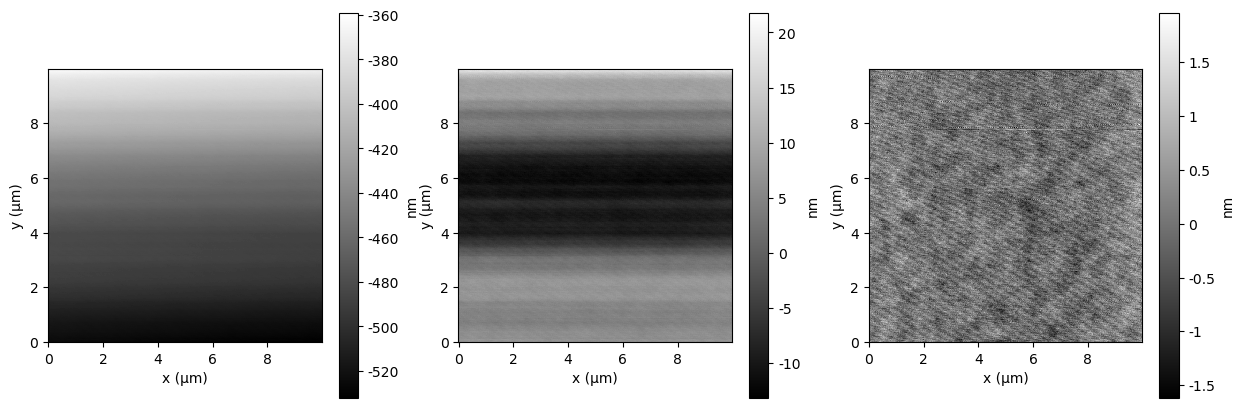

In [8]:
fig, ax = plt.subplots(1,3, figsize = (15,5))

piz.plotting.image(z, ax=ax[0], pixel_size=px, cmap = 'gray')
piz.plotting.image(levelled, ax = ax[1], pixel_size=px, cmap = 'gray')
piz.plotting.image(flattened, ax = ax[2], pixel_size=px, cmap = 'gray')


In [7]:
r = piz.analysis.roughness(flattened)
print(f"Roughness Sq is {r.sq*1e9:.2f} nm")

Roughness Sq is 0.34 nm
